## Анализ  данных

In [9]:
!pip install -q phik


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from data.data import stat_chart, stat_chart_cat, stat_chart2

# загрузка инструментов для корреляционного анализа
import phik
from phik import phik_matrix
from phik.report import plot_correlation_matrix 

%matplotlib inline

%load_ext autoreload
%autoreload 2

### Загрузка файлов

In [2]:
train = pd.read_csv(config.path_train)
test = pd.read_csv(config.path_test)

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
print(f'Number of objects and features in train subset {train.shape}')
print(f'Number of objects and features in test subset {test.shape}')


Number of objects and features in train subset (891, 12)
Number of objects and features in test subset (418, 11)


In [6]:
train.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
422,423,0,3,"Zimmerman, Mr. Leo",male,29.0,0,0,315082,7.8750,NaN,S
229,230,0,3,"Lefebre, Miss. Mathilde",female,NaN,3,1,4133,25.4667,NaN,S
372,373,0,3,"Beavan, Mr. William Thomas",male,19.0,0,0,323951,8.0500,NaN,S
815,816,0,1,"Fry, Mr. Richard",male,NaN,0,0,112058,0.0000,B102,S
111,112,0,3,"Zabour, Miss. Hileni",female,14.5,1,0,2665,14.4542,NaN,C


In [7]:
print('Number of missing values in train subset')
train.isna().sum()

Number of missing values in train subset


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
print('Number of missing values in test subset')
test.isna().sum()

Number of missing values in test subset


PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

It should be filled

In [9]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
test.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


Check dublicates

In [11]:
train['PassengerId'].duplicated().sum()

np.int64(0)

Разделим признаки на количественные и категорильные:

In [12]:
drop_cols = []
drop_cols.append('PassengerId')
train = train.drop(columns=['PassengerId'])

In [13]:
#numerical features
num_col = train.select_dtypes(include='number').columns

In [14]:
#categorcal features
cat_col = train.select_dtypes(exclude='number').columns

### Таргет на трейне (Survived)

In [15]:
num_col[0]

'Survived'

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


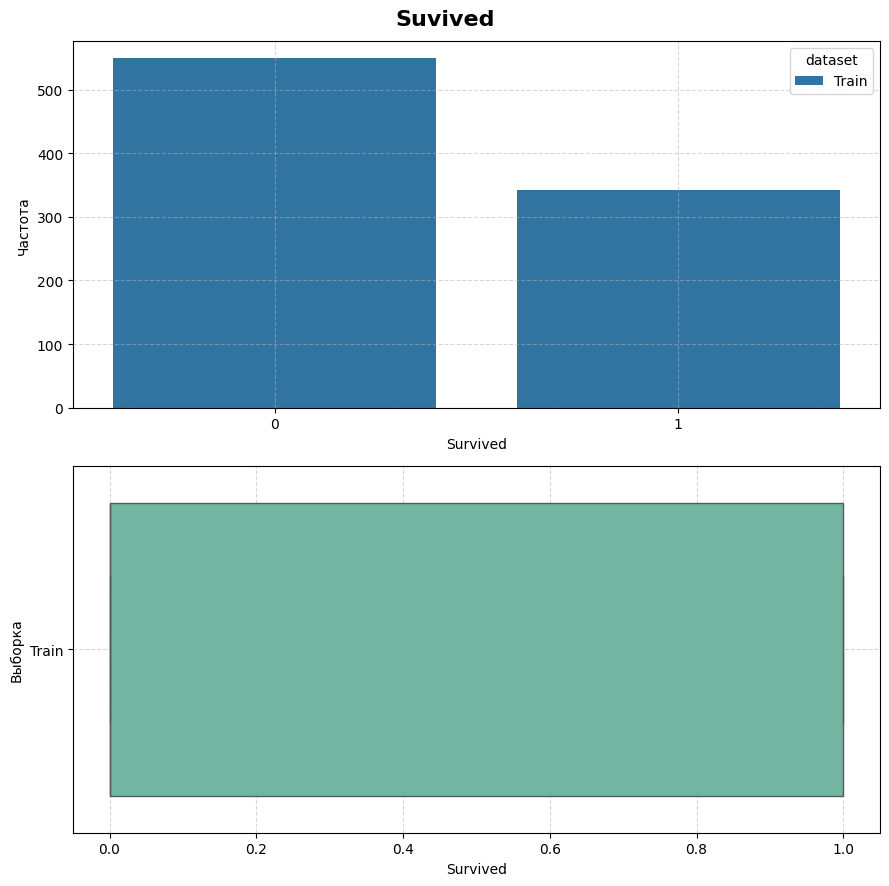

In [ ]:
col = num_col[0]
stat_chart2(train, col_name=col, title="Survived", xlabel_name=f'{col}', plot= 'countplot', figsize=(9,9))

**Recap**: There some inbalance in target. Не забыть использовать стратификацию при делении выборки.

### Количественные данные

#### Трейн

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


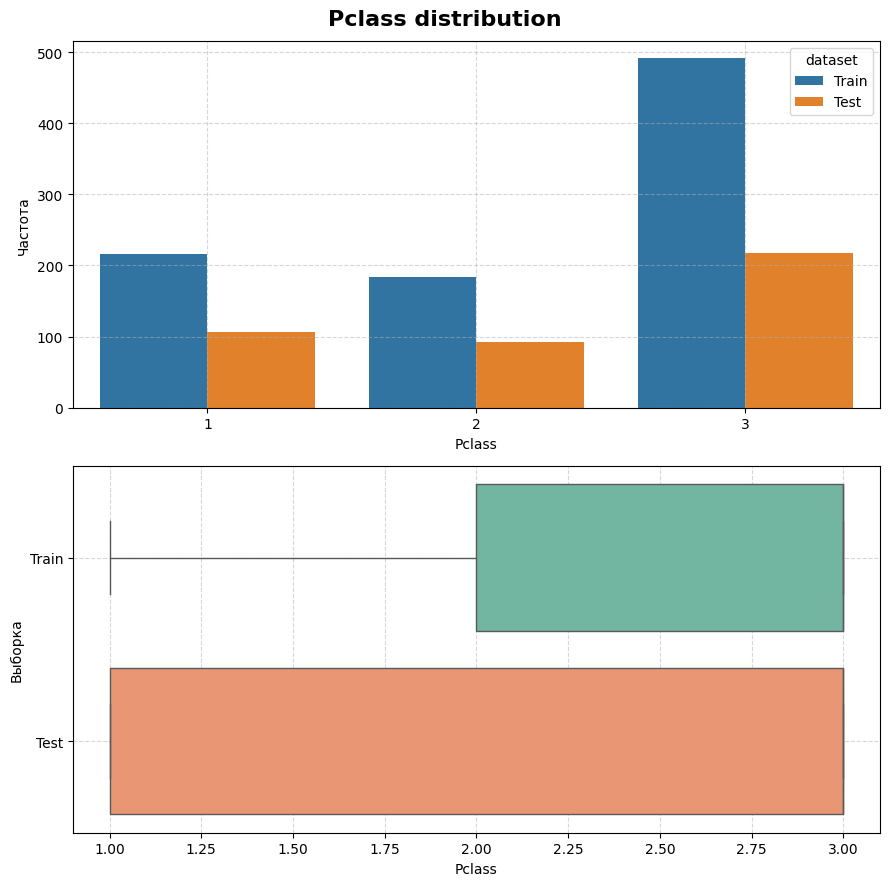

In [17]:
col = num_col[1]
stat_chart2(train, data2 = test, col_name=col, title=f'{col} distribution', xlabel_name=f'{col}', plot= 'countplot', figsize=(9,9))

Сильный дисбаланс в данных по классу. что тоже лагично 3й самый низкий, скорее всего дешевый класса больше всего. Сравнить со стоимостями.

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


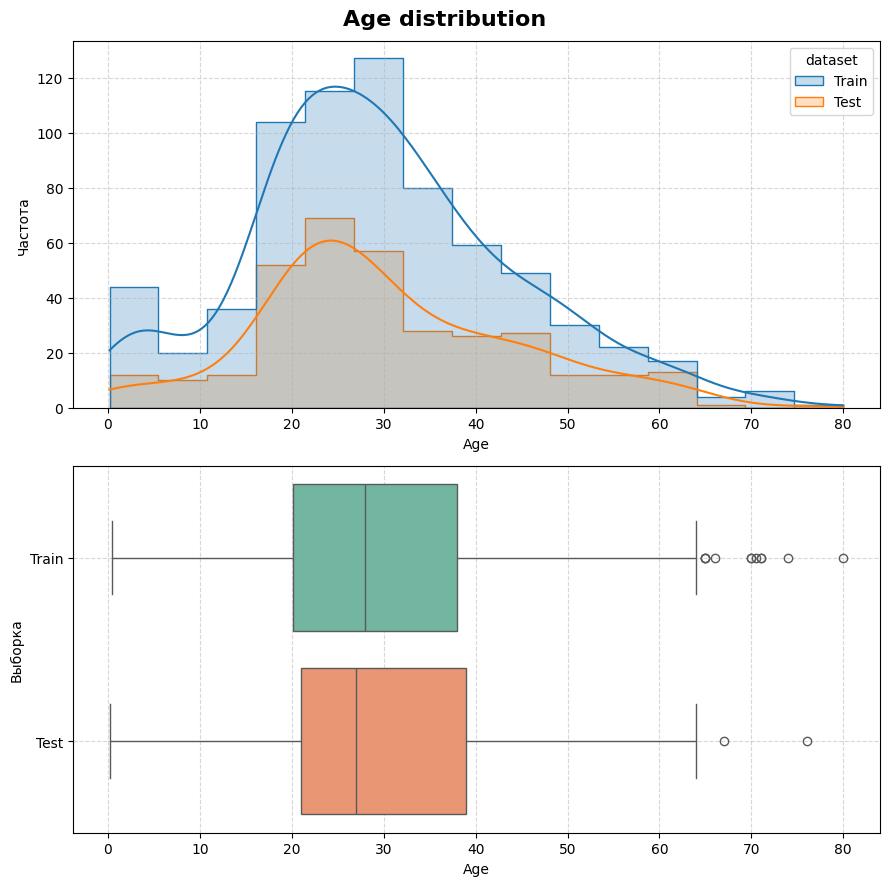

In [46]:
col = num_col[2]
stat_chart2(train, data2=test, col_name=col, title=f'{col} distribution', xlabel_name=f'{col}', plot= 'histplot',  figsize=(9,9))

Есть несколько выбросов. деление по классами и таргету разбивает равномерные графики

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


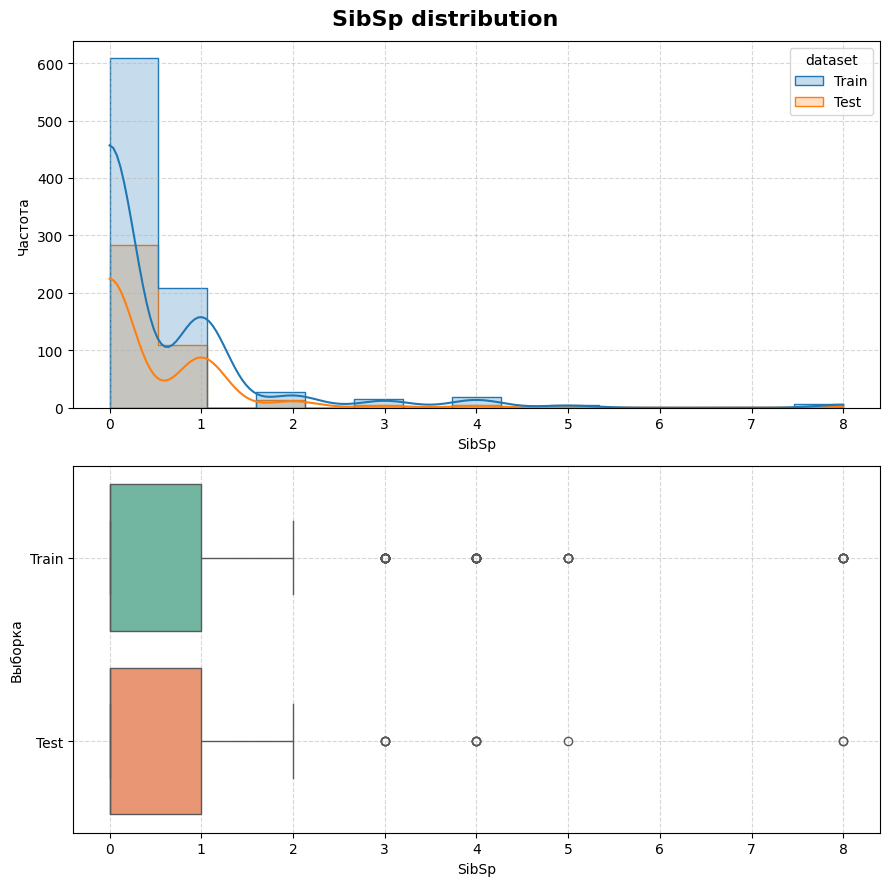

In [19]:
col = num_col[3]
stat_chart2(train, data2= test, col_name=col, title=f'{col} distribution', xlabel_name=f'{col}', plot= 'histplot', figsize=(9,9))

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


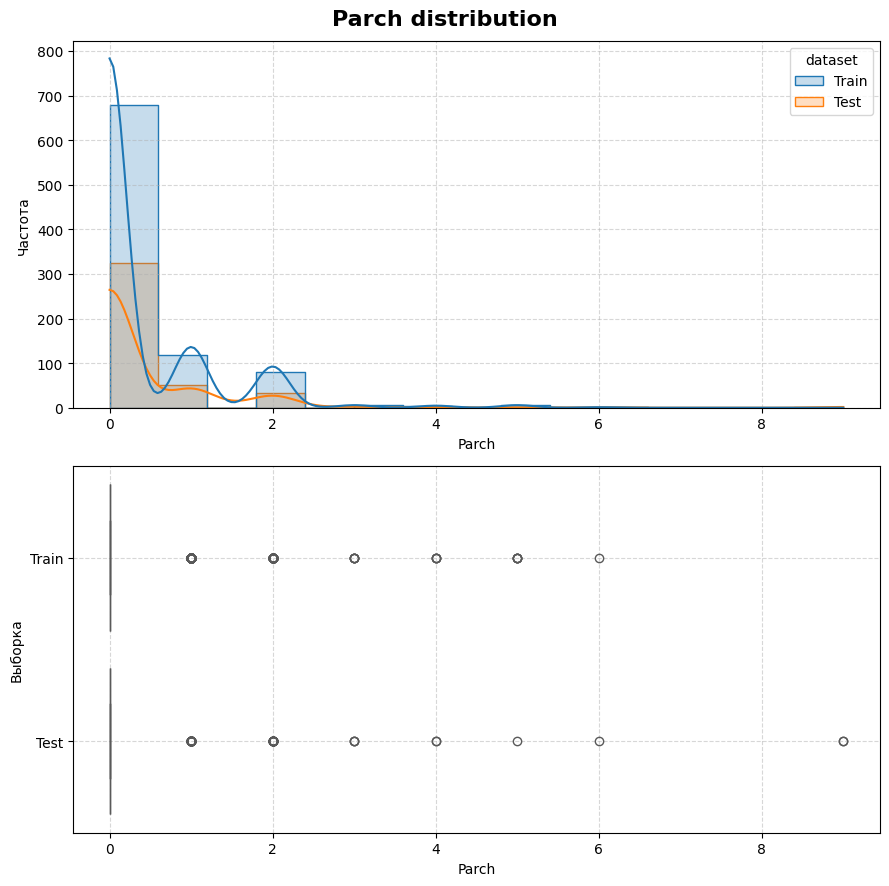

In [20]:
col = num_col[4]
stat_chart2(train, data2=test, col_name=col, title=f'{col} distribution', xlabel_name=f'{col}', plot= 'histplot', figsize=(9,9))

c:\work\titanic\data\data.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_data, x=col_name, y='dataset', ax=axs[1], orient='h', palette='Set2')


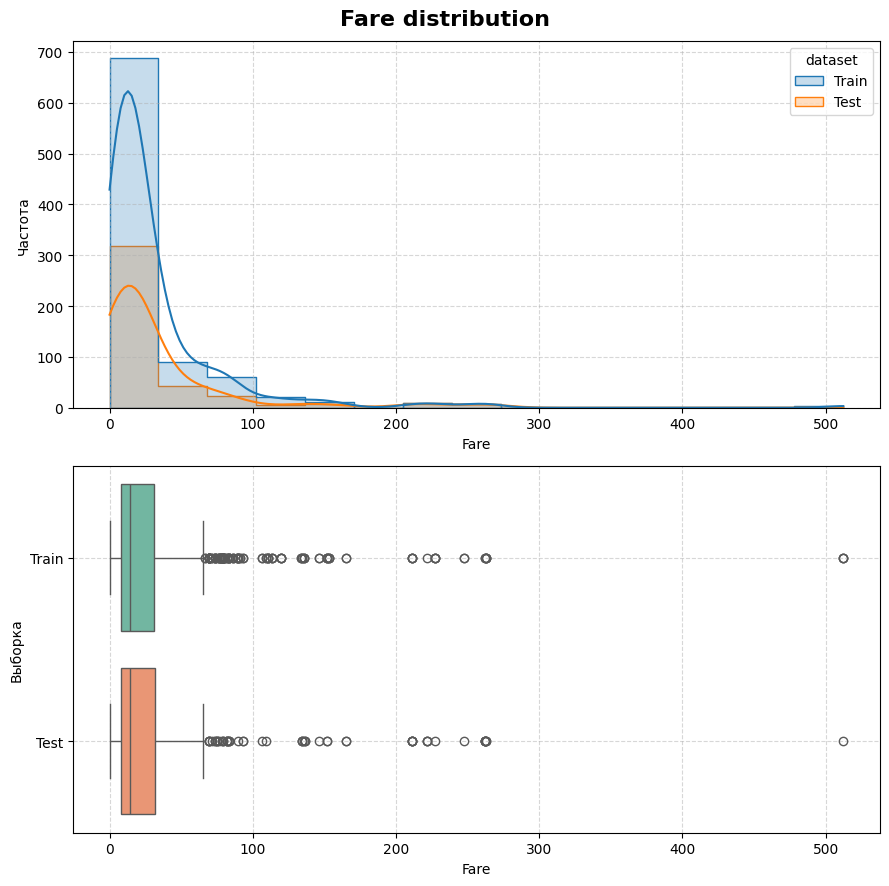

In [21]:
col = num_col[5]
stat_chart2(train, data2=test, col_name=col, title=f'{col} distribution', xlabel_name=f'{col}', plot= 'histplot', figsize=(9,9))

**Вывод:** распределение по возрасту примерно совпадает с обучающей выборкой

### Категориальные признаки

In [22]:
print(f'Категориальных признаков - {len(cat_col)} шт.')

Категориальных признаков - 5 шт.


In [23]:
cat_col

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')

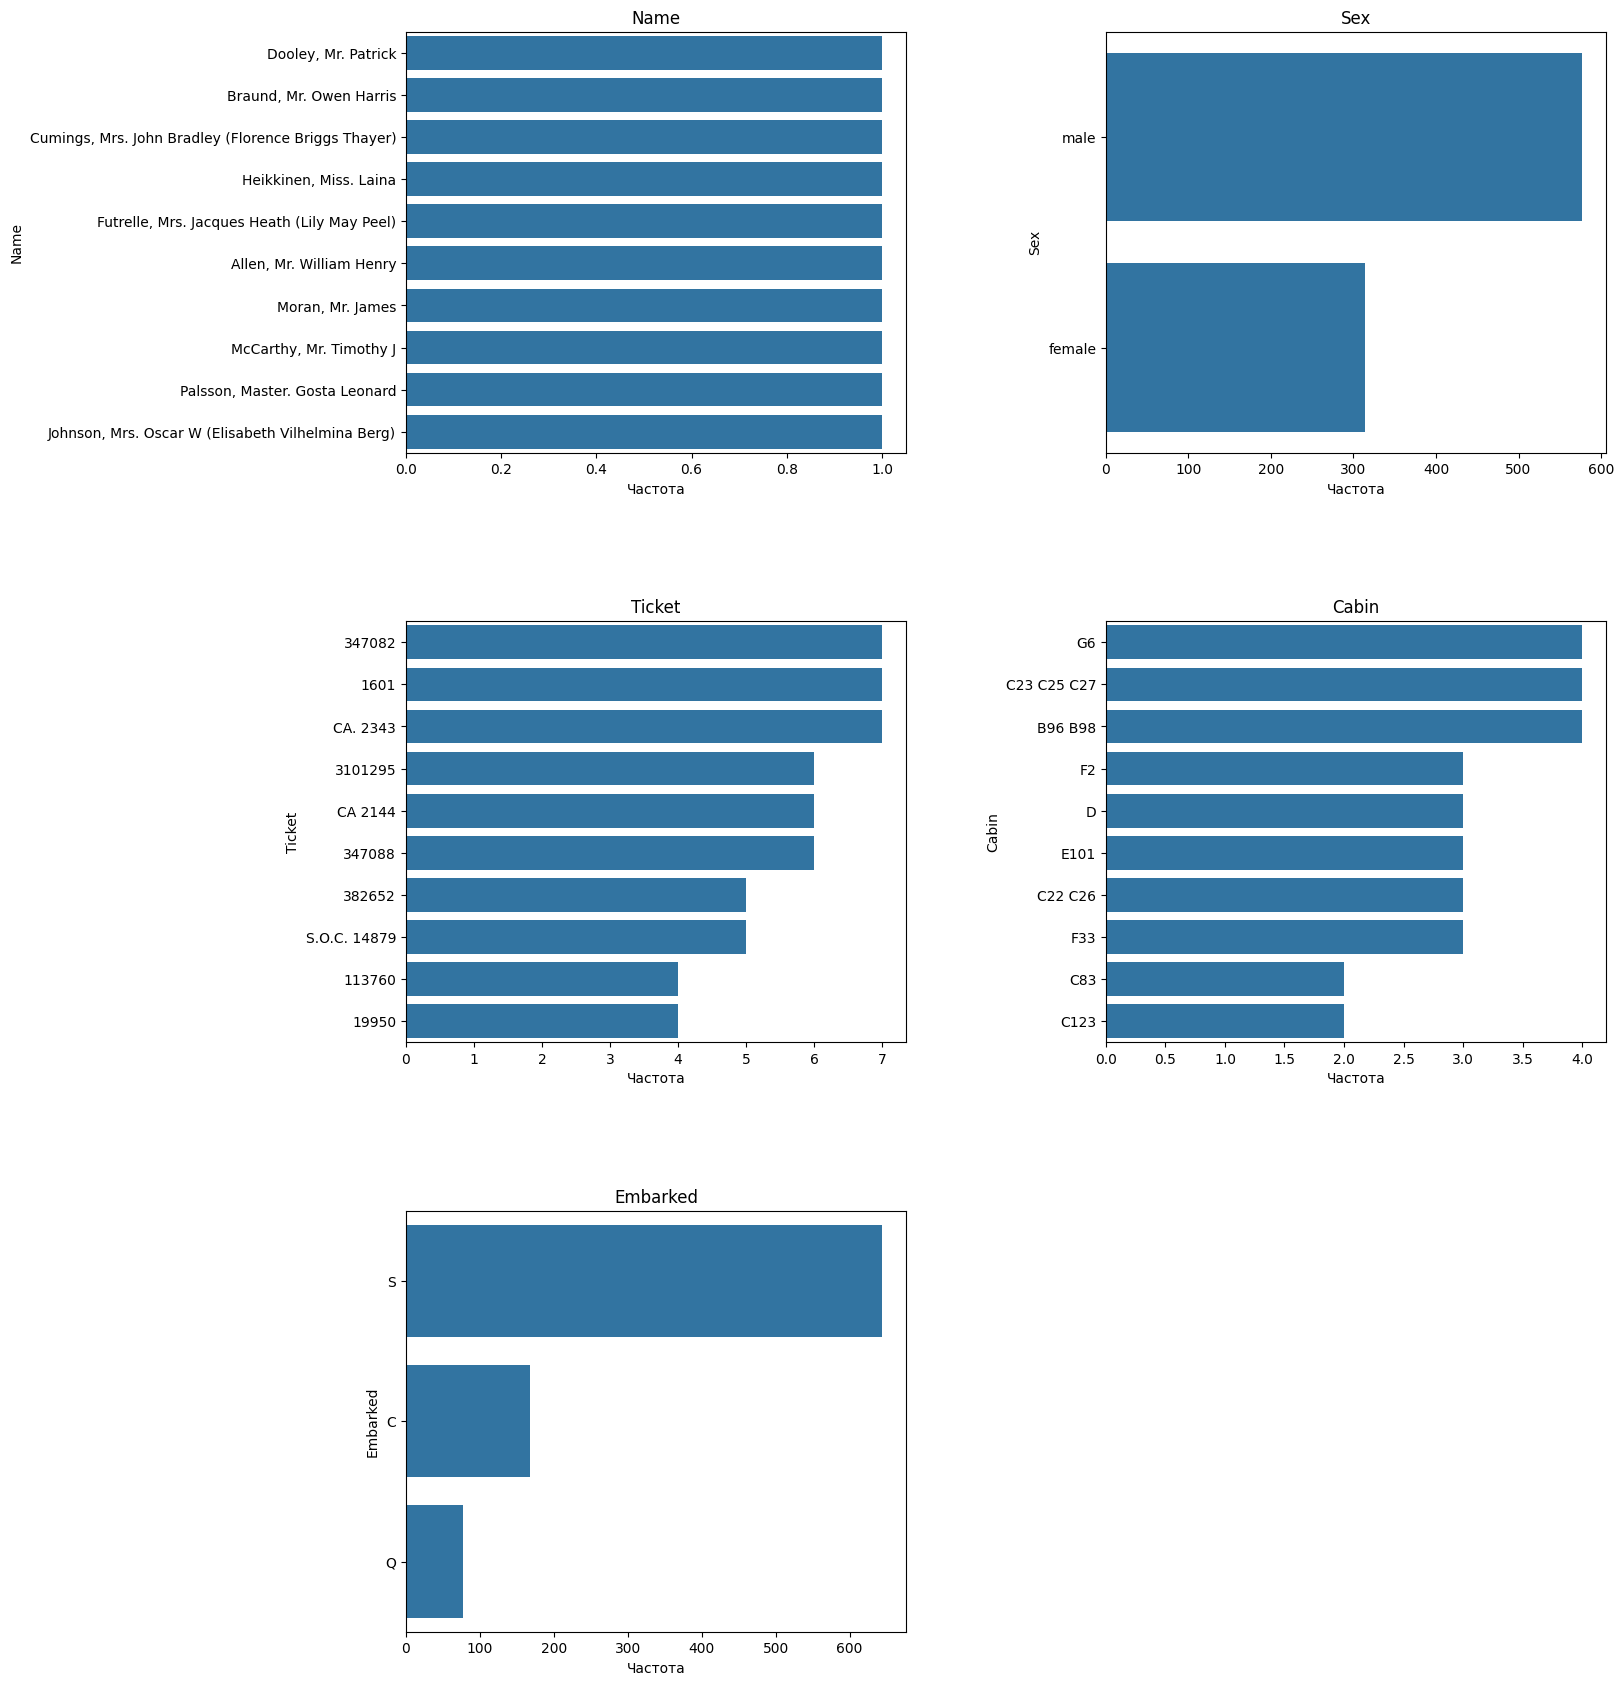

In [24]:
stat_chart_cat(train, cat_cols=cat_col)

В категориальных данных дисбаланс в признаках Embarked и Sex.

In [25]:
train.sort_values('Ticket')

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
504,1,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.500,B79,S
257,1,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.500,B77,S
759,1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.500,B77,S
262,0,1,"Taussig, Mr. Emil",male,52.0,1,1,110413,79.650,E67,S
558,1,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.650,E67,S
...,...,...,...,...,...,...,...,...,...,...,...
235,0,3,"Harknett, Miss. Alice Phoebe",female,NaN,0,0,W./C. 6609,7.550,NaN,S
92,0,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.175,E31,S
219,0,2,"Harris, Mr. Walter",male,30.0,0,0,W/C 14208,10.500,NaN,S
540,1,1,"Crosby, Miss. Harriet R",female,36.0,0,2,WE/P 5735,71.000,B22,S


- Можно  выделить людей, у которых есть общий билет скорее всего они знакомы; создадим столбец `relatives`, обозначающий наличие знакомых на борту;
- по номеру кабины можно выдлить сектор (по первой букве) разделим на 2 части это столбец и пустые значени заполним как "no_data";
Имена можно удалить, т.к. их данные достаточно уникальны, хотя можно найти что-то интересное;

In [26]:
#создадим признак наличия знакомых
train['relatives'] = train.groupby('Ticket')['Ticket'].transform('count') - 1

In [27]:
drop_cols.append('Ticket')
train = train.drop(columns = ['Ticket'])

In [ ]:
#разделим номера кают на номера и блоки.
train[['Cabin_num', 'Cabin_sec']] = train['Cabin'].str.split(n=1, regex=True, pat='(?<=^.)', expand=True)

In [30]:
drop_cols.append('Cabin')
train = train.drop(columns = ['Cabin'])

In [35]:
drop_cols.append('Name')
train = train.drop(columns = ['Name'])

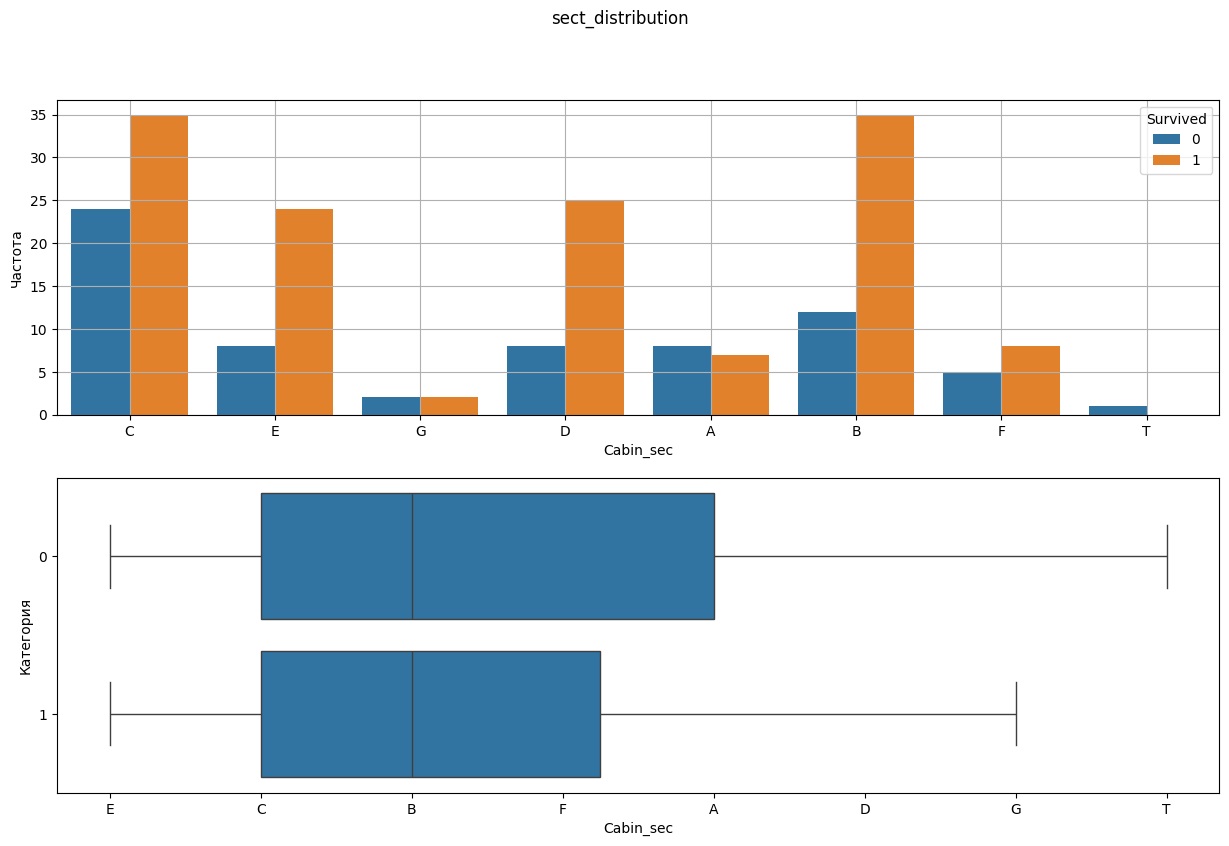

In [31]:
#распределение новых признаков
stat_chart(train,  col_name='Cabin_num', plot='countplot', title='sect_distribution', xlabel_name='Cabin_sec', hue='Survived')

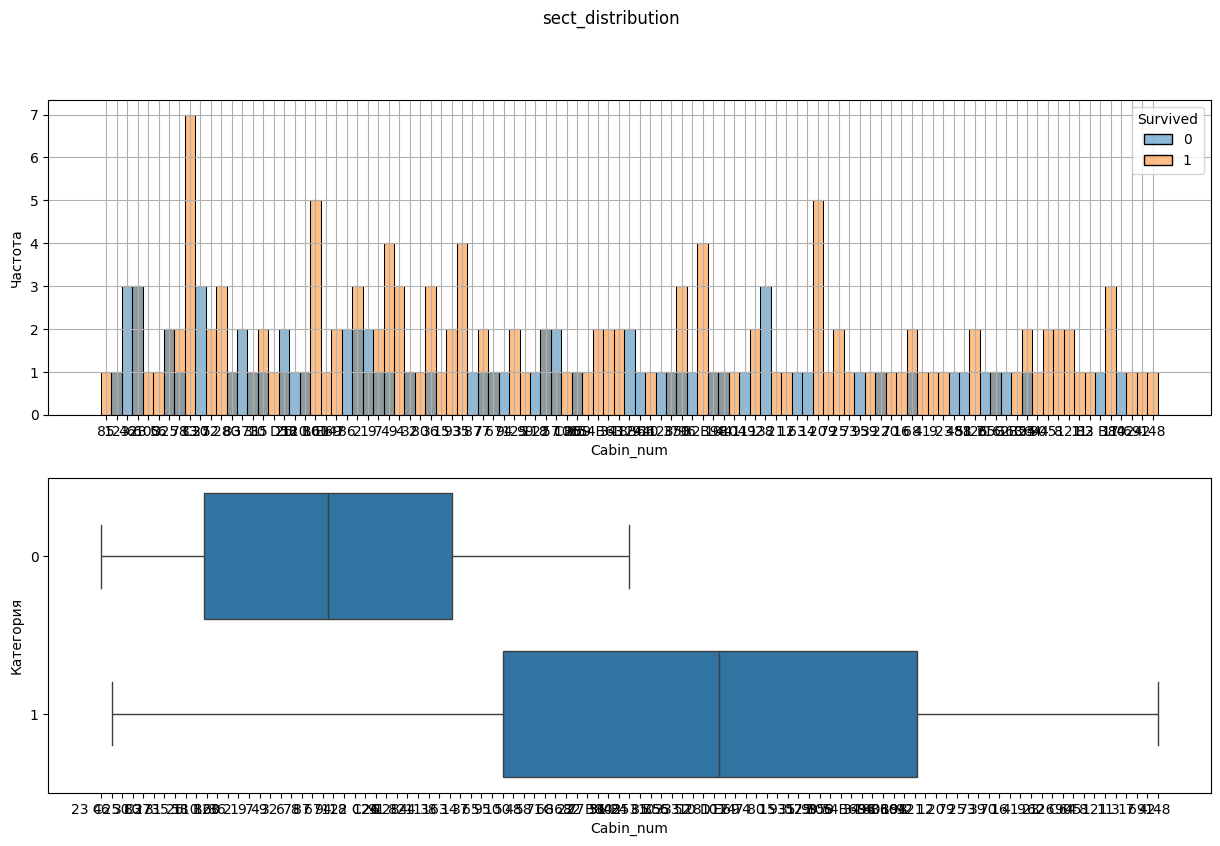

In [39]:
stat_chart(train,  col_name='Cabin_sec', plot='histplot',    title='sect_distribution', xlabel_name='Cabin_num', hue='Survived')

In [ ]:
#заполним пустые значения заглушкой
#train[['Cabin_num', 'Cabin_sec']] = train[['Cabin_num', 'Cabin_sec']].fillna('no_data')

### Простроение матрица корреляции

In [86]:
#построение матрицы корреляции
cm = train.phik_matrix(interval_cols=['Fare'])

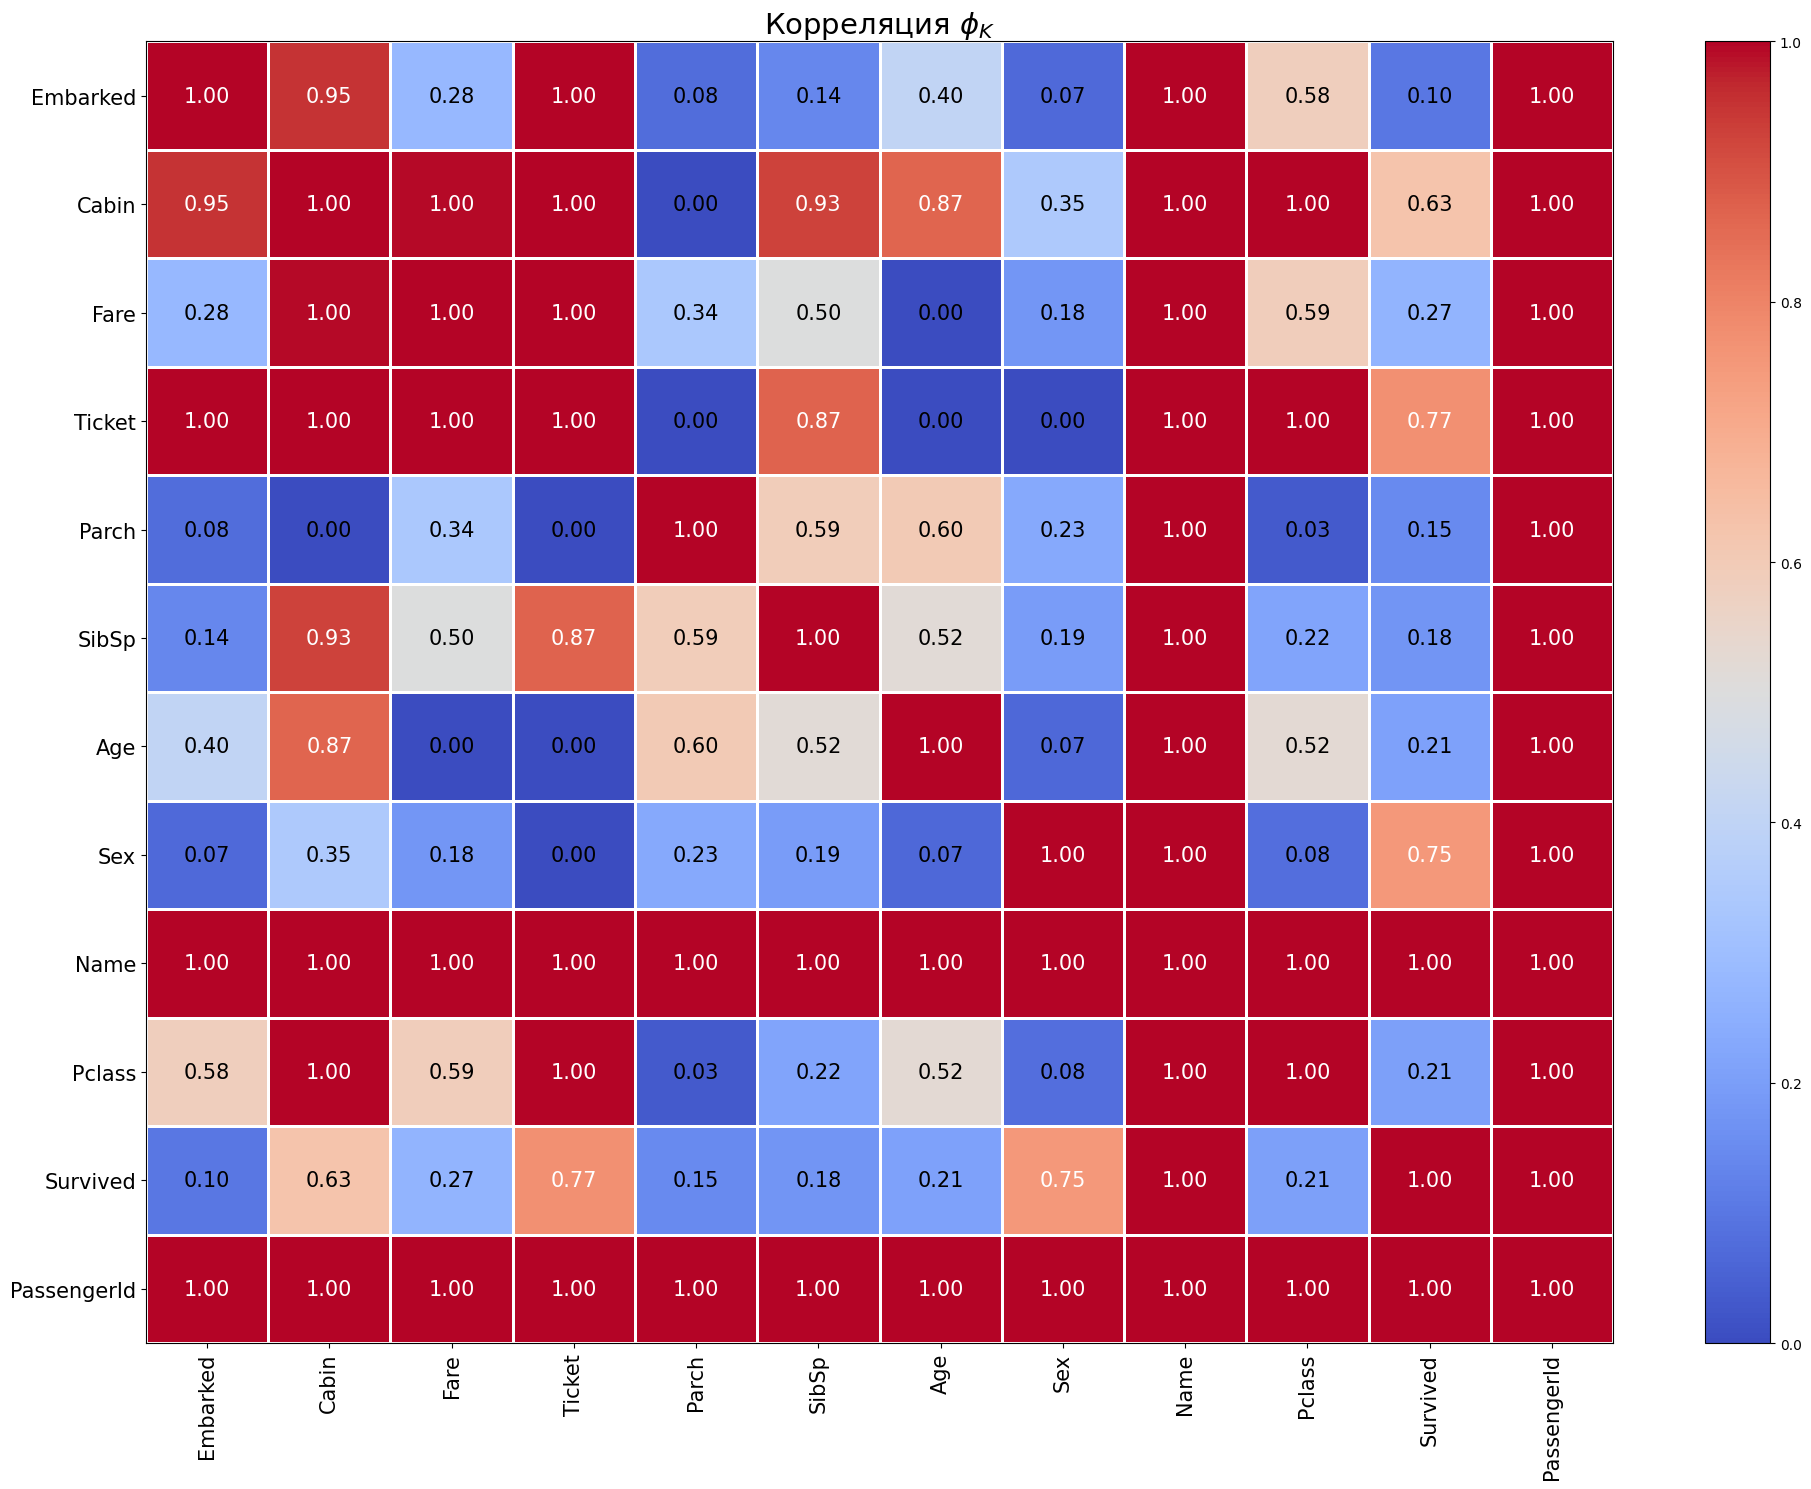

In [87]:
#визуализация матрицы
plot_correlation_matrix(
    cm.values,
    x_labels=cm.columns,
    y_labels=cm.index,
    vmin=0, vmax=1, color_map='coolwarm',
    title=r'Корреляция $\phi_K$',
    fontsize_factor=1.5,
    figsize=(20, 15)
)

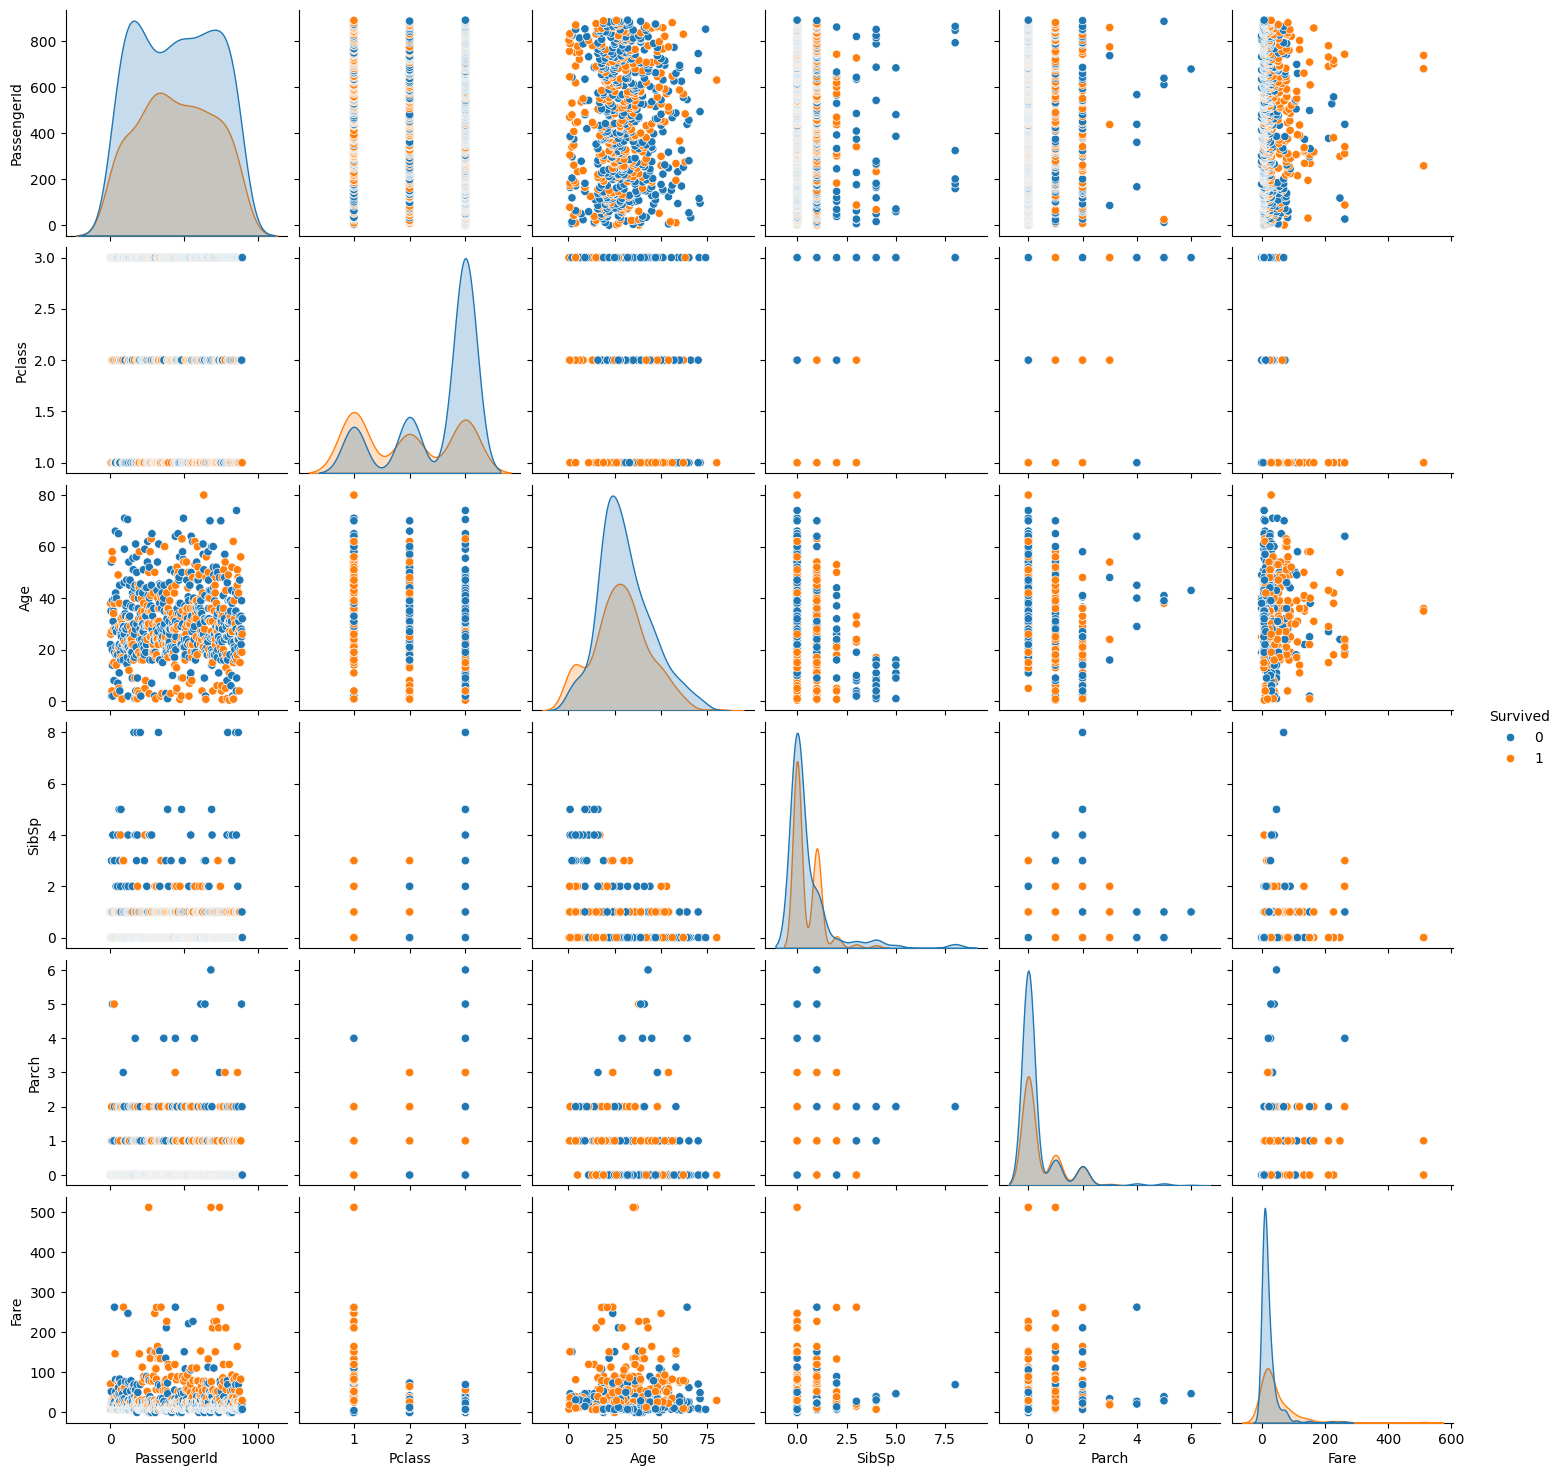

In [88]:
sns.pairplot(train, hue='Survived', kind="scatter", markers="o")
plt.show()

In [89]:
train['Age'].fillna(train.groupby(by=['Pclass', 'Parch'])['Age'].transform('mean'))

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    12.403226
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64

In [90]:
train.query('Fare<400 & SibSp<6')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [91]:
train.query('Fare>400')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C


In [92]:
train.query('Fare<400 & SibSp<6')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [93]:
train['Cabin']

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object

In [94]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [95]:
from data.data import stat_chart

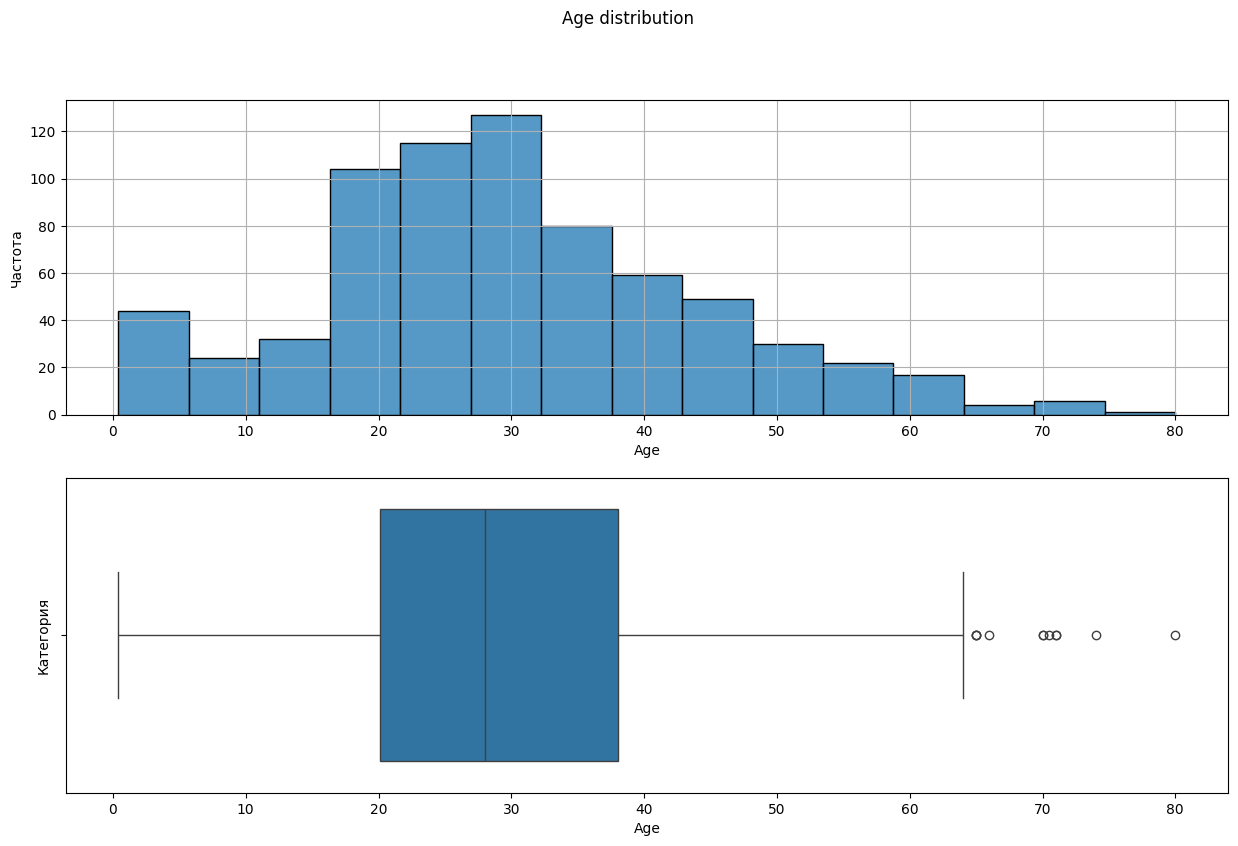

In [96]:
stat_chart(train, col_name='Age', title='Age distribution', xlabel_name='Age')

In [97]:
def load_data(self, path_csv:str = None,
                  path_excel:str = None,
                   query:str = None):
        if path_csv!=None:
            
            if os.path.exists(path_csv):
                print(f'Loading data from {path_csv}')
                if path.split(sep='.')[-1]=='csv':
                    return pd.read_csv(path_csv)
                elif path.split(sep='.')[-1]=='xlsx':
                    return pd.read_excel(path_excel)

        else:
            print('Path not exists')
            pass

In [98]:
load_data(config.path_train)

Path not exists


In [99]:
if path_train!=None:
    if os.path.exists(path_train):
        print(f'Loading data from {path_train}')
        if path.split(sep='.')[-1]=='csv':
            return pd.read_csv(path_train)
        elif path.split(sep='.')[-1]=='xlsx':
            return pd.read_excel(path_train)

        else:
            print('Path not exists')
        pass

SyntaxError: 'return' outside function (1221765773.py, line 5)

In [ ]:
from data.data import load_data

In [ ]:
data = load_data(config.source_config)

In [ ]:
for x  in data:
    print(x)

Start loading csv
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500  

In [ ]:
load_data(config.source_config)

NameError: name 'load_data' is not defined

In [ ]:
config.source_config['path']

'data\\train.csv'

In [ ]:
from preprop import prepr

In [ ]:
from config import preprocessor_config

In [ ]:
a = prepr(preprocessor_config)

In [ ]:
a.history['anomaly']

{'rule_1': {'rows_before': 891,
  'rows_after': 3,
  'removed_rows': 888,
  'column': 'Fare',
  'condition': 'more',
  'border': 500},
 'rule_2': {'rows_before': 3,
  'rows_after': 0,
  'removed_rows': 3,
  'column': 'Age',
  'condition': 'more',
  'border': 65}}

In [ ]:
X_train, X_test, y_train, y_test = a.run(train)

Удаление дубликатов. Размер исходной таблицы:(891, 12)


array([[-2.10062687, -0.58015407,  0.        , ...,  2.        ,
         0.        ,  1.        ],
       [-0.38404343, -0.47376494,  0.        , ...,  1.        ,
         0.        ,  0.        ],
       [ 1.36311529, -0.16695381,  1.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [-0.16564859,  0.47781183,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [ 1.29031701,  0.02506062,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.19834281, -0.53309018,  0.        , ...,  1.        ,
         0.        ,  0.        ]], shape=(140, 11))

In [ ]:
a.history

{'remove_duplicates': {'rows_before': 891,
  'rows_after': 891,
  'removed_duplicates': 0,
  'distinct_cols': None},
 'anomaly': {'rule_1': {'rows_before': 891,
   'rows_after': 888,
   'removed_rows': 3,
   'column': 'Fare',
   'condition': 'less',
   'border': 500},
  'rule_2': {'rows_before': 888,
   'rows_after': 700,
   'removed_rows': 188,
   'column': 'Age',
   'condition': 'less',
   'border': 65}},
 'feat_eng': {},
 'split': {'test_size': 0.2,
  'random_state': 42,
  'shuffle': True,
  'row_before': 700,
  'train_rows': 560,
  'test_rows': 140,
  'stratified': True},
 'transformed': {'completion': True, 'shape_after': (140, 11)}}

In [106]:
import train as t
import data
import preprop

In [ ]:
train = data.data.load_data(source_config=config.source_train)

Start loading csv


train

In [ ]:
test = data.data.load_data(source_config=config.source_test)

Start loading csv


In [ ]:
tr = prepr(config=preprocessor_config)

In [102]:
X_train, X_test, y_train, y_test = tr.run(train)

Удаление дубликатов. Размер исходной таблицы:(891, 12)


In [112]:
b = t.trainer(config.trainer_config)

In [113]:
b.fit(X_train, y_train)

In [120]:
b.models_results

{'logistic_regression': {'score': np.float64(0.7297611972682555),
  'params': {'C': 0.5},
  'metric': 'f1'},
 'knn_class': {'score': np.float64(0.7468743253417285),
  'params': {'n_neighbors': 5, 'weights': 'uniform'},
  'metric': 'f1'}}

In [119]:
t.evaluate(b.best_model, X_test, y_test)

([0,
  0,
  1,
  1,
  0,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  0,
  0],
 {'accuracy': 0.8214285714285714,
  'f1': np.float64(0.7863247863247863),
  'recall': np.float64(0.7931034482758621),
  'precision': np.float64(0.7796610169491526)})

In [1]:
import sklearn
import scipy

print("sklearn:", sklearn.__version__)
print("scipy:", scipy.__version__)

sklearn: 1.4.2
scipy: 1.14.0
